# AP 155 Lab Exercise
---
## Exercise 13: Ordinary differential equations

_Instructions_:
- **Report Figure:** Generate two figures: (1) famous Lorenz butterfly $x-z$ plot and (2) Van-der-Pol oscillator phase space plot
- **Report Discussion:** Explain the dynamics in the figures. Discuss how both Euler's method and Runge-Kutta method work in a nutshell. Distinguish the advantages and disadvantages between Euler vs RK4.
- **Code**: Complete the code and ensure it is functional, error-free, readable, and efficient (where needed). Include concise Markdown documentation highlighting the critical steps of your algorithm for each problem.

### Student Information
- _Full Name (Last Name, First Name)_: Maraña, Kyle
- _Student No._: 2024-14996
- _Section_: THR-WX-1

### Grading Information (c/o Lab Instructor)
- [Rubrics description link](https://drive.google.com/file/d/1BMSlPot2Mc7XLu0eo4S8I8gLBsIadbCL/view)

| Criteria | Score | Subtotal |
| --- | --- | --- |
| Report figure | XX | 20 |
| Report discussion | XX | 20|
| Code readability | XX | 20 |
| Code efficiency | XX | 20 |
| Code appropriateness  | XX | 20 |
| **TOTAL** | XXX | 100 |

_Date and Time Scored (MM/DD/YYYY HH:MM AM/PM):_

---
## Section 1: Report

### Report figure
![A](fig1.png)
**Figure 1. Lorenz system time series ($\sigma$=10, $\rho$=28, $\beta$=8/3)**
This figure shows x(t), y(t), and z(t) from rk4gen, starting at (0, 1, 0) and running to t = 50 with 5000 points. After a short transient, all three variables oscillate irregularly with no repeating pattern. x and y swing between positive and negative values, while z stays positive. The sign changes in x and y mark the switches between the two lobes of the attractor. This shows deterministic chaos: the equations contain no randomness, yet the motion never settles into a fixed point or a periodic cycle.
![A](fig2.png)
**Figure 2. Phase Space Plot of Lorenz Equation (Strange Attractor)**
This figure plots the same solution as three projections: y vs x, z vs x, and z vs y. The z–x panel is the familiar butterfly-shaped strange attractor. The trajectory loops around one lobe several times, then switches to the other at unpredictable moments. Curves appear to cross in these 2D projections, but in the full 3D space the trajectory never intersects itself. The motion stays bounded, yet it never repeats and never converges to a point or closed orbit.
![A](fig3.png)
**Figure 3. Simple Harmonic Oscillator: Position vs Time**
Rewriting ẍ = −ω²x as the system [x, v] and integrating with ω=1 over t = 0–50 gives a smooth sinusoid. Starting from x = 1 and v = 0, x oscillates between +1 and −1 with a period of 2π ≈ 6.28, so about eight cycles fit in the interval. The amplitude shows no visible decay or growth, consistent with energy being conserved. RK4's small truncation error is what keeps the amplitude steady at this step size.
![A](fig4.png)
**Figure 4. Simple Harmonic Oscillator: Comparing Amplitudes**
This figure overlays solutions for x₀ = 1 and x₀ = 2. The x₀ = 2 curve has twice the amplitude, but both curves cross zero and reach their peaks at the same times. The period is therefore independent of amplitude, which is the isochronism of a linear restoring force.
![A](fig5.png)
**Figure 5. Anharmonic Oscillator: Comparing Amplitudes**
With the cubic restoring force ẍ = −ω²x³, the same two starting amplitudes now behave differently. The x₀ = 2 curve oscillates noticeably faster than the x₀ = 1 curve. A larger displacement feels a much stronger restoring force, so the particle accelerates more and completes each cycle sooner. For this force the period scales roughly as 1/amplitude, so doubling the amplitude about halves the period. The waveform is also less sinusoidal than in Figure 4.
![A](fig6.png)
**Figure 6. Phase Space Plot of Anharmonic Oscillator**
Plotting dx/dt against x gives a closed loop for each amplitude, with the x₀ = 2 loop enclosing the x₀ = 1 loop. A closed loop means the motion is periodic and energy is conserved. The loops are squarer than the ellipses of the harmonic case, because the cubic force is weak near x = 0 and rises steeply at large |x|. The larger orbit also reaches a much higher peak velocity, since it starts with more potential energy.
![A](fig7.png)
**Figure 7. Phase Space Plot of van der Pol Oscillator**
This figure shows dx/dt vs x for μ = 1, 2, and 4 over t = 0–20, starting from (1, 0). The nonlinear damping term adds energy when |x| < 1 and removes it when |x| > 1. Each trajectory therefore spirals onto a single closed limit cycle that does not depend on the starting point. For μ = 1 the cycle is smooth and nearly oval. As μ increases, the loop becomes more distorted, with sharp corners and fast jumps in velocity, which is relaxation-type oscillation.

### Report discussion
In Problem 1, the Lorenz system (σ=10, ρ=28, β=8/3) shows deterministic chaos. The time series of x, y, and z fluctuate irregularly without repeating, and the x-z phase plot forms a bounded, two-lobed strange attractor. The trajectory circles one lobe, then switches unpredictably to the other. Nearby trajectories diverge exponentially, yet the motion stays confined and never settles into a fixed point or periodic orbit. In Problem 2, the linear harmonic oscillator gives sinusoidal motion with a constant amplitude and a period of 2π, independent of the starting displacement. The cubic anharmonic oscillator breaks this, the larger-amplitude solution oscillates faster because the restoring force grows steeply with displacement. Both oscillators conserve energy, so their phase-space plots are closed loops, which are ellipses for the harmonic case and squarer for the cubic case. The van der Pol oscillator behaves differently. Its nonlinear damping adds energy when |x| < 1 and removes it when |x| > 1, so every trajectory spirals onto the same limit cycle. This cycle is smooth and nearly oval for μ = 1 and becomes a sharp-cornered relaxation oscillation as μ increases to 4.

Numerically, eulergen and rk4gen both divide [a, b] into n points with step h = (b−a)/(n−1) and advance the state vector one step at a time. Euler's method takes the slope at the start of each step and moves along that straight line, yₙ₊₁ = yₙ + h·f(tₙ, yₙ). Its global error is O(h). RK4 samples the slope four times per step: k₁ at the start, k₂ and k₃ at the midpoint, and k₄ at the end. It then averages them with weights 1, 2, 2, 1, so yₙ₊₁ = yₙ + (k₁ + 2k₂ + 2k₃ + k₄)/6. Its global error is O(h⁴). Euler's advantages are that it is simple to code and cheap, with one function evaluation per step. Its disadvantages are that it needs a very small h for accuracy and drifts, for example gaining energy in the pendulum and oscillators. RK4's advantage is that it is far more accurate at the same step size, with much smaller energy drift, which is why it was used for the chaotic and oscillatory systems. Its disadvantages are four function evaluations per step and a more complex implementation, though it can use larger steps to offset the cost.

### Other comments
- yes

---
## Section 2: Code

In [1]:
import matplotlib.pyplot as plt
import numpy as np

import seaborn as sns # Guide: https://seaborn.pydata.org/tutorial/introduction.html
sns.set_theme(style="darkgrid")

rng = np.random.default_rng(67)

### Practice: Simple pendulum
$$\frac{d^2\theta}{dt^2}=-\frac{g}{l}\sin\theta $$

- Variables: ${\theta}$
- Parameters: ${g, l}$

To solve a second-order ODE, we reduce it to two first-order ODEs.
Let $\theta = y_0$ and $\omega = \frac{d\theta}{dt} = y_1$.
The system becomes:
\begin{align}
\frac{d \theta}{dt} &= \omega \\
\frac{d \omega}{dt} &= -\frac{g}{l}\sin(\theta)
\end{align}

Text(0.5, 1.0, 'yes')

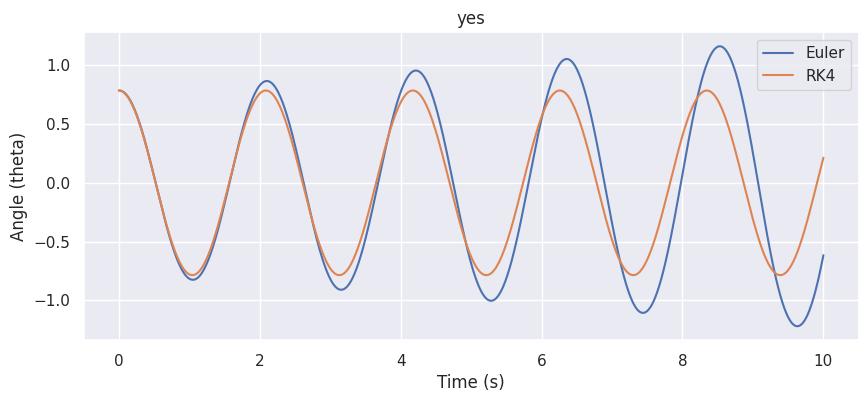

In [13]:
# practice mode

# global constants
g = 9.81
l = 1.0

def pendulum_ode(t, R):
    # R is a vector containing the two variables theta, omega
    theta, omega = R
    f0 = omega
    f1 = -(g/l) * np.sin(theta)
    return np.array([f0, f1])

# given time interval from 0 to 10 seconds sampled at 1000 pts, define a, b, n
a = 0.0
b = 10.0
n = 1000

# init conds (arbitrary): pi/4 angle, 0 initial velocity
theta0 = np.pi/4
omega0 = 0.0
yinit = np.array([theta0, omega0])

t, Y_euler = eulergen(pendulum_ode, a, b, n, yinit)
t, Y_rk4 = rk4gen(pendulum_ode, a, b, n, yinit)

plt.figure(figsize=(10,4))
plt.plot(t, Y_euler[:,0], label='Euler')
plt.plot(t, Y_rk4[:,0], label='RK4')
plt.legend()
plt.xlabel('Time (s)')
plt.ylabel('Angle (theta)')
plt.title('yes')

### Exercise 1: Simultaneous 1st order ODEs

One of the most celebrated sets of differential equations in physics is the Lorenz equations
\begin{align}
\frac{dx}{dt} &= \sigma(y-x) \\
\frac{dy}{dt} &= \rho x - y - xz\\
\frac{dz}{dt} &= xy - \beta z \\
\end{align}
where $\mu$, $\rho$, and $\beta$ are constants. (The names $\mu$, $\rho$, and $\beta$ are odd, but traditional --- they
are always used in these equations for historical reasons.)

These equations were first studied by Edward Lorenz in 1963, who derived them from a simplified model of weather patterns. The reason for their fame is that they were one of the first incontrovertible examples of *deterministic chaos*, the occurrence of apparently random motion even though there is no randomness built into the equations. We encountered a different example of chaos in the logistic map.

**(a)** Write a program to solve the Lorenz equations for the case $\sigma = 10$, $\rho = 28$, and $\beta =\frac{8}{3}$ in the range from $t = 0$ to $t = 50$ with initial conditions $(x,y,z) =(0, 1,0)$. Plot the trajectory $(x(t), y(t), z(t))$ for different parameter values. One trajectory should clearly illustrate the chaotic behavior of the Lorenz attractor.

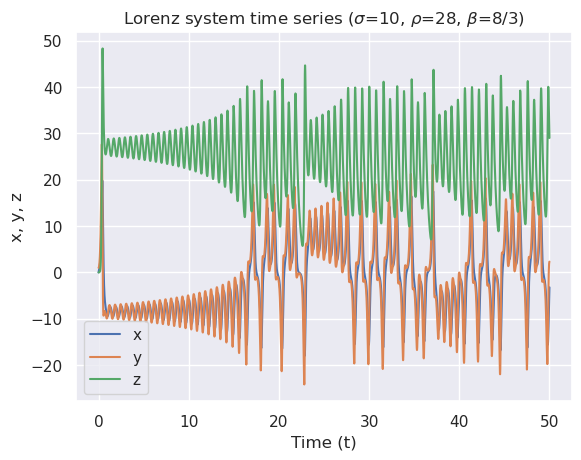

In [8]:
# parameters
sigma = 10
rho = 28
beta = 8/3
init_con = np.array([0.0, 1.0, 0.0])

t_range = np.linspace(0, 50, 1000)

def lorenz_ode(t, init_con):

  g0 = sigma * (init_con[1] - init_con[0])
  g1 = rho * init_con[0] - init_con[1] - init_con[0] * init_con[2]
  g2 = init_con[0] * init_con[1] - beta * init_con[2]

  return np.array([g0, g1, g2])

n = 5000

t, L_rk4 = rk4gen(lorenz_ode, t_range[0], t_range[-1], n, init_con)

plt.plot(t, L_rk4[:,0], label='x')
plt.plot(t, L_rk4[:,1], label='y')
plt.plot(t, L_rk4[:,2], label='z')
plt.xlabel('Time (t)')
plt.ylabel('x, y, z')
plt.title(r'Lorenz system time series ($\sigma$=10, $\rho$=28, $\beta$=8/3)')
plt.legend()
plt.savefig('fig1.png')
plt.show()

**(b)** Modify your program to produce a plot of $z$ against $x$. You should see a picture of the famous "strange attractor" of the Lorenz equations, a lop-sided butterfly-shaped plot that never repeats itself.

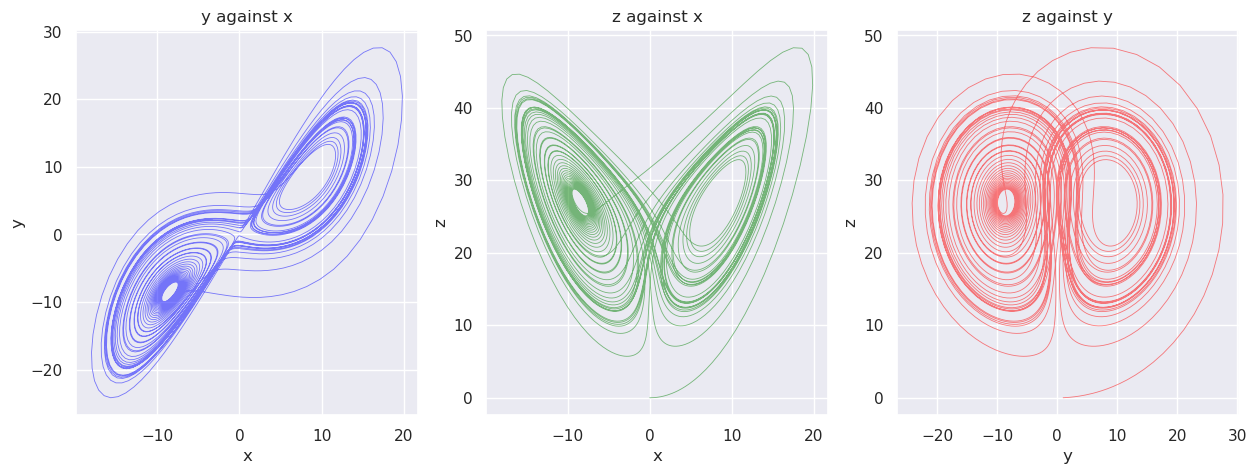

In [16]:
fig, axs = plt.subplots(1, 3, figsize=(15, 5))

axs[0].plot(L_rk4[:,0], L_rk4[:,1], color='blue', linewidth='0.6', alpha=0.5)
axs[0].set(title='y against x', xlabel='x', ylabel='y')
axs[1].plot(L_rk4[:,0], L_rk4[:,2], color='green', linewidth='0.6', alpha=0.5)
axs[1].set(title='z against x', xlabel='x', ylabel='z')
axs[2].plot(L_rk4[:,1], L_rk4[:,2], color='red', linewidth='0.6', alpha=0.5)
axs[2].set(title='z against y', xlabel='y', ylabel='z')
plt.savefig('fig2.png')
plt.show()

#### Problem 1 code summary

This code builds general integrators, eulergen and rk4gen, that take a derivative function, an interval [a, b], an initial state, and a number of points, then return the time array and a state matrix. Writing every equation as a first-order system lets one solver handle the pendulum, Lorenz, and oscillator problems. The pendulum compares Euler and RK4 accuracy. The Lorenz system (σ=10, ρ=28, β=8/3) is solved with rk4gen from (0, 1, 0) over t = 0–50, since RK4 limits error growth in a chaotic system, and plotted as time series and x–y, x–z, y–z projections.

### Exercise 2: Second-order ODEs (Harmonic and anharmonic oscillators)

The simple harmonic oscillator arises in many physical problems, in mechanics, electricity and magnetism, and condensed matter physics, among other areas. Consider the standard oscillator equation
$$ \frac{d^2x}{dt^2} = - \omega^2 x $$.

**(a)** Turn this second-order equation into two coupled first-order equations. Then write a program to solve them for the case $\omega = 1$ in the range from $t=0$ to $t= 50$. A second-order equation requires two initial conditions, one on $x$ and one on its derivative. For this problem use $x = 1$ and $\frac{dx}{dt} = 0$ as initial conditions. Have your program
make a graph showing the value of $x$ as a function of time.

$$ \frac{dx}{dt} = y$$
$$ \frac{dy}{dt} = - \omega^2 x $$

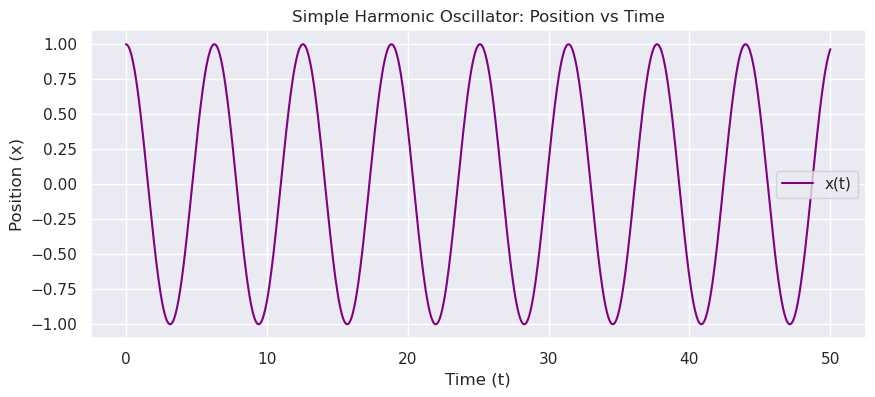

In [11]:
omega = 1.0

def harmonic_ode(t, yvals): # yvals consists of [x, y] where y = dx/dt
    x_val, y_val = yvals
    f0 = y_val
    f1 = -(omega**2) * x_val
    return np.array([f0, f1])

# parameters
a_SHO = 0.0
b_SHO = 50.0
n_SHO = 1000
yinit_Ha = np.array([1.0, 0.0]) # x(0) = 1, dx/dt(0) = 0

# solve using RK4
t_SHOa, Y_Ha = rk4gen(harmonic_ode, a_SHO, b_SHO, n_SHO, yinit_Ha)

# plotting
plt.figure(figsize=(10, 4))
plt.plot(t_SHOa, Y_Ha[:, 0], label='x(t)', color='purple')
plt.title("Simple Harmonic Oscillator: Position vs Time")
plt.xlabel("Time (t)")
plt.ylabel("Position (x)")
plt.legend()
plt.savefig('fig3.png')
plt.show()

**(b)** Now increase the amplitude of the oscillations by making the initial value of $x$ bigger --- say $x = 2$ --- and confirm that the period of the oscillations stays roughly the same.

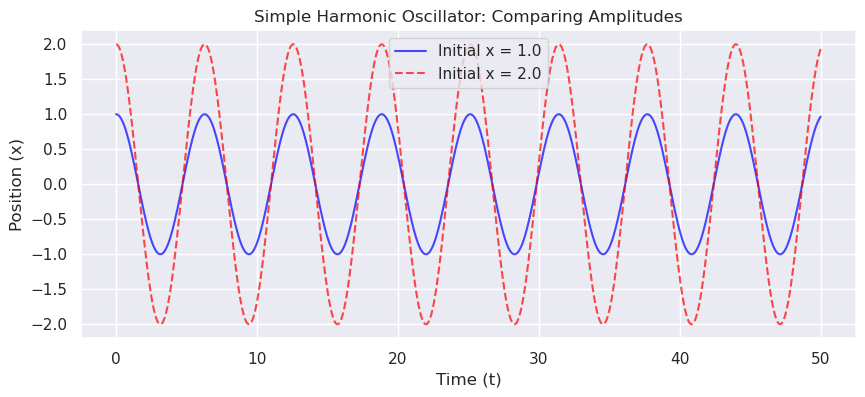

In [12]:
# solve with initial condition x(0) = 2.0, dx/dt(0) = 0.0
yinit_Hb = np.array([2.0, 0.0])
t_SHOb, Y_Hb = rk4gen(harmonic_ode, a_SHO, b_SHO, n_SHO, yinit_Hb)

# plotting to compare
plt.figure(figsize=(10, 4))
plt.plot(t_SHOa, Y_Ha[:, 0], label='Initial x = 1.0', color='blue', alpha=0.7)
plt.plot(t_SHOb, Y_Hb[:, 0], label='Initial x = 2.0', color='red', alpha=0.7, linestyle='--')
plt.title("Simple Harmonic Oscillator: Comparing Amplitudes")
plt.xlabel("Time (t)")
plt.ylabel("Position (x)")
plt.legend()
plt.savefig('fig4.png')
plt.show()

**(c)** Modify your program to solve for the motion of the anharmonic oscillator described by the equation
$$ \frac{d^2 x}{dt} = -\omega^2 x^3.$$

Again take $\omega= 1$ and initial conditions $x = 1$ and $dx/dt = 0$ and make a plot of the motion of the oscillator. Again increase the amplitude. You should observe that the oscillator oscillates faster at higher amplitudes. (You can try lower amplitudes too if you like, which should be slower.)

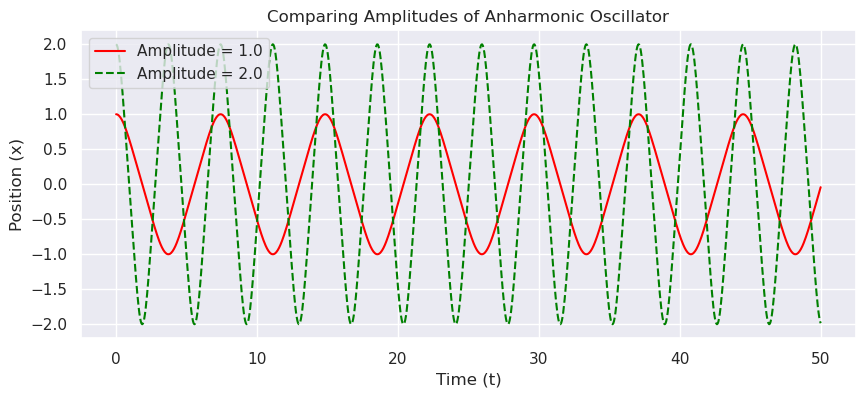

In [13]:
omega_AH = 1.0

def anharmonic_ode(t, yvals): # yvals is [x, y] where y = dx/dt
    x_val, y_val = yvals
    f0 = y_val
    f1 = -(omega_AH**2) * (x_val**3)
    return np.array([f0, f1])

# parameters
a_AH = 0.0
b_AH = 50.0
n_AH = 1000

# solve for amplitude = 1.0
yinit_AH1 = np.array([1.0, 0.0])
t_AH, Y_AH1 = rk4gen(anharmonic_ode, a_AH, b_AH, n_AH, yinit_AH1)

# solve for amplitude = 2.0
yinit_AH2 = np.array([2.0, 0.0])
_, Y_AH2 = rk4gen(anharmonic_ode, a_AH, b_AH, n_AH, yinit_AH2)

# plotting to compare
plt.figure(figsize=(10, 4))
plt.plot(t_AH, Y_AH1[:, 0], label='Amplitude = 1.0', color='red')
plt.plot(t_AH, Y_AH2[:, 0], label='Amplitude = 2.0', color='green', linestyle='--')
plt.title("Comparing Amplitudes of Anharmonic Oscillator")
plt.xlabel("Time (t)")
plt.ylabel("Position (x)")
plt.legend()
plt.savefig('fig5.png')
plt.show()

**(d)** Modify your program so that instead of plotting $x$ against $t$, it plots $\frac{dx}{dt}$ against $x$, i.e., the "velocity" of the oscillator against its "position." Such a plot is called a *phase space* plot.

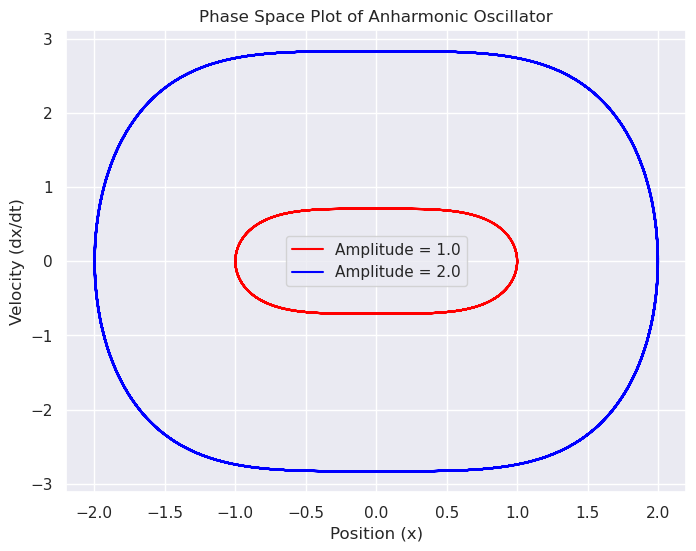

In [14]:
plt.figure(figsize=(8, 6))
plt.plot(Y_AH1[:, 0], Y_AH1[:, 1], label='Amplitude = 1.0', color='red', linewidth=1.5)
plt.plot(Y_AH2[:, 0], Y_AH2[:, 1], label='Amplitude = 2.0', color='blue', linewidth=1.5)
plt.title("Phase Space Plot of Anharmonic Oscillator")
plt.xlabel("Position (x)")
plt.ylabel("Velocity (dx/dt)")
plt.legend()
plt.grid(True)
plt.savefig('fig6.png')
plt.show()

**(e)** The van der Pol oscillator, which appears in electronic circuits and in laser physics, is described by the equation
$$\frac{d^2x }{dt^2} - \mu(1-x^2)\frac{dx}{dt} + x = 0 $$
Use the same techniques as the one above (i.e. rewrite into 2 1st-order ODEs). Modify your program to solve this equation from $t=0$ to $t=20$ and hence make a phase space plot for the van der Pol oscillator with $\omega=1$, $\mu = 1$, and initial conditions $x = 1$ and $dx/dt = 0$. Try it also for $\mu=2$ and $\mu=4$ (still with $\omega = 1$). Make sure you use a small enough value of the time interval $h$ to get a smooth, accurate phase space plot.

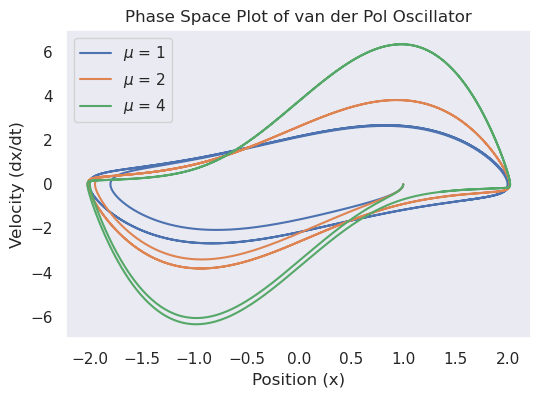

In [15]:
omega_e = 1
mu_e = [1, 2, 4]

init_con_e = np.array([1.0, 0.0])
t_range_e = np.array([0, 20])

def vanderPol_ode(t, init_con):
  k0 = init_con[1]
  k1 = (mu * (1.0 - (init_con[0]**2))) * init_con[1] - init_con[0]
  return np.array([k0, k1])

n_e = 5000

plt.figure(figsize=(6, 4))
for mu in mu_e:
  t_e, vanderPol_rk4 = rk4gen(vanderPol_ode, t_range_e[0], t_range_e[-1], n_e, init_con_e)
  plt.plot(vanderPol_rk4[:, 0], vanderPol_rk4[:, 1], label=f'$\mu$ = {mu}')

plt.title("Phase Space Plot of van der Pol Oscillator")
plt.xlabel("Position (x)")
plt.ylabel("Velocity (dx/dt)")
plt.legend()
plt.grid()
plt.savefig('fig7.png')
plt.show()

#### Problem 2 code summary

Include a brief summary (2–3 sentences) at the bottom of your code outlining the purpose of the script and its core algorithm. Focus on explaining why you wrote the code this way and the reasoning behind your implementation choices.

This code rewrites each second-order oscillator equation as a first-order system so the same rk4gen solver can integrate it. The harmonic and cubic anharmonic oscillators are solved with ω=1 for x₀ = 1 and 2 to contrast amplitude-independent and amplitude-dependent periods, and the anharmonic case is also plotted as velocity against position. The van der Pol equation is then integrated from t = 0 to 20 in a loop over μ = 1, 2, 4 with 5000 points to keep each limit cycle smooth.

---
## Section 3: Notes

In [2]:
# forward Euler's method

def euler(f,a,b,n,yinit):
    h = (b-a)/(n-1)
    xs = a + np.arange(n)*h
    ys = np.zeros(n)
    y = yinit
    for j,x in enumerate(xs):
        ys[j] = y
        y += h*f(x, y)
    return xs, ys

In [3]:
# 2nd order Runge-Kutta method

def rk2(f,a,b,n,yinit):
    h = (b-a)/(n-1)
    xs = a + np.arange(n)*h
    ys = np.zeros(n)
    y = yinit
    for j,x in enumerate(xs):
        ys[j] = y
        k1 = h*f(x, y)
        k2 = h*f(x+0.5*h, y+0.5*k1)
        y += k2
    return xs, ys

In [4]:
# 4th order Runge-Kutta method (1 equation only, use the code below for simultaneous eqns)

def rk4(f,a,b,n,yinit):
    h = (b-a)/(n-1)
    xs = a + np.arange(n)*h
    ys = np.zeros(n)
    y = yinit
    for j,x in enumerate(xs):
        ys[j] = y
        k0 = h*f(x, y)
        k1 = h*f(x+h/2, y+k0/2)
        k2 = h*f(x+h/2, y+k1/2)
        k3 = h*f(x+h, y+k2)
        y += (k0 + 2*k1 + 2*k2 + k3)/6
    return xs, ys

In [7]:
# execution
a, b, n, yinit = 0.05, 0.49, 5, 19.53

def f(x,y):
    ...

xs, ys = euler(f,a,b,n,yinit); print(ys)
plt.plot(xs,ys, label='Euler')
xs, ys = rk2(f,a,b,n,yinit); print(ys)
plt.plot(xs,ys, label='RK2')
xs, ys = rk4(f,a,b,n,yinit); print(ys)
plt.plot(xs,ys, label='RK4')
plt.legend()
plt.show()

TypeError: unsupported operand type(s) for *: 'float' and 'NoneType'

#### Solving IVP problem of 2 simultaneous ODEs

In [5]:
def fs(x,yvals):
    y0, y1 = yvals
    f0 = y1
    f1 = - (30/(1-x**2))*y0 + ((2*x)/(1-x**2))*y1
    return np.array([f0, f1])

def rk4gen(fs,a,b,n,yinits):
    h = (b-a)/(n-1)
    xs = a + np.arange(n)*h
    ys = np.zeros((n, yinits.size))
    yvals = np.copy(yinits)
    for j,x in enumerate(xs):
        ys[j,:] = yvals
        k0 = h*fs(x, yvals)
        k1 = h*fs(x+h/2, yvals+k0/2)
        k2 = h*fs(x+h/2, yvals+k1/2)
        k3 = h*fs(x+h, yvals+k2)
        yvals += (k0 + 2*k1 + 2*k2 + k3)/6
    return xs, ys

a, b, n = 0.05, 0.49, 12
yinits = np.array([0.0926587109375, 1.80962109375])
xs, ys = rk4gen(fs,a,b,n,yinits)
print(ys)

[[ 0.09265871  1.80962109]
 [ 0.16241651  1.66496084]
 [ 0.22481633  1.44262901]
 [ 0.27687631  1.1492782 ]
 [ 0.3159291   0.79398005]
 [ 0.33971857  0.38822519]
 [ 0.34649662 -0.05407672]
 [ 0.33511993 -0.51659705]
 [ 0.3051467  -0.98058819]
 [ 0.25693343 -1.42488364]
 [ 0.19173167 -1.82589807]
 [ 0.1117848  -2.15762739]]


In [6]:
def eulergen(f, a, b, n, yinit):
    h = (b-a)/(n-1)
    xs = a + np.arange(n)*h
    ys = np.zeros((n, len(yinit)))
    y = np.array(yinit, dtype=float)
    for j, x in enumerate(xs):
        ys[j, :] = y
        y += h*f(x, y)
    return xs, ys

### Plotting

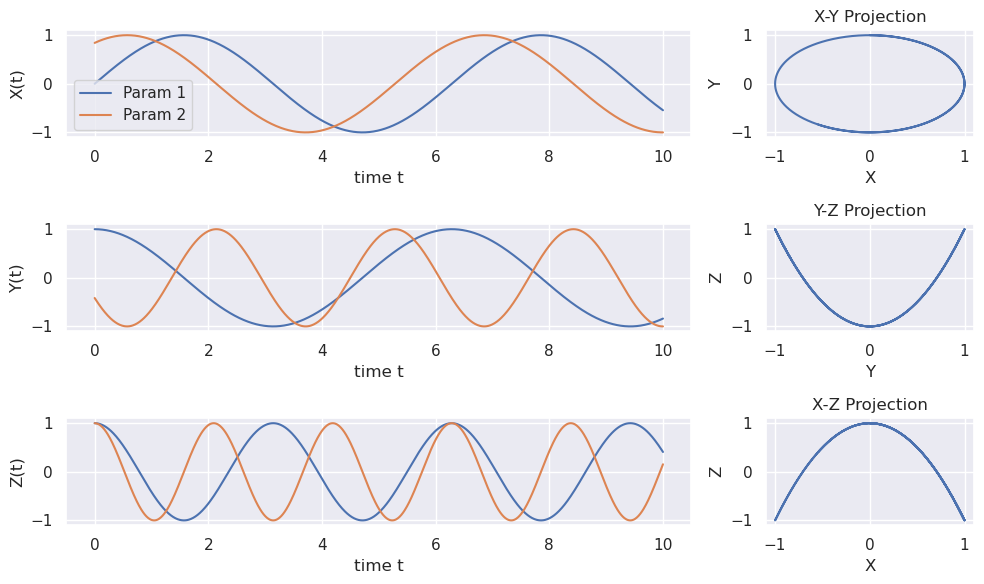

In [7]:
# SAMPLE DATA ONLY
t = np.linspace(0, 10, 1000)
x = np.sin(t)
y = np.cos(t)
z = np.cos(2*t)

x1 = np.sin(t + 1)
y1 = np.cos(2*t + 2)
z1 = np.cos(3*t)

# See: https://stackoverflow.com/questions/10388462/matplotlib-different-size-subplots
fig, axs = plt.subplots(3, 2, figsize=(10, 6), gridspec_kw={'width_ratios': [3, 1]})

# Time series
axs[0, 0].plot(t, x, label="Param 1")
axs[0, 0].plot(t, x1, label="Param 2")
axs[0, 0].legend()
axs[0, 0].set_ylabel("X(t)")

axs[1, 0].plot(t, y)
axs[1, 0].plot(t, y1)
axs[1, 0].set_ylabel("Y(t)")

axs[2, 0].plot(t, z)
axs[2, 0].plot(t, z1)
axs[2, 0].set_ylabel("Z(t)")

# add xlabel to all time series
for ax in axs[:, 0]:
    ax.set_xlabel("time t")

# Phase plot
axs[0, 1].plot(x, y)
axs[0, 1].set(title="X-Y Projection", xlabel="X", ylabel="Y")

axs[1, 1].plot(y, z)
axs[1, 1].set(title="Y-Z Projection", xlabel="Y", ylabel="Z")

axs[2, 1].plot(x, z)
axs[2, 1].set(title="X-Z Projection", xlabel="X", ylabel="Z")

fig.tight_layout()